# XXZ模型：Jordan-Wigner変換とBethe仮説

XXZ模型をJordan-Wigner変換でフェルミオンの問題に書き換え、$\Delta\neq0$では自由フェルミオンにならない（4次の相互作用が残る）ことを確かめる。$\Delta=0$（XX模型）は自由フェルミオンとして解き、$\Delta\neq0$は代わりに**Bethe仮説**で基底エネルギーを求める。

変換の定義・一般的な規則・BdG形式は [methods/02_jordan_wigner.ipynb](../../methods/02_jordan_wigner.ipynb)、Bethe仮説の一般論は [methods/06_bethe_ansatz.ipynb](../../methods/06_bethe_ansatz.ipynb)、模型の定義は [00_model.ipynb](00_model.ipynb) を参照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/operators.py, ed.py）と XXZ 模型の定義（src/qmb/models.py）
from qmb.operators import neel_state
from qmb.ed import ground_state, time_evolve_expectation
from qmb.models import xxz_hamiltonian as hamiltonian, staggered_magnetization, xxz_hamiltonian_sector

# Jordan-Wigner変換の一般的な関数（src/qmb/free_fermion.py）
from qmb.free_fermion import bdg_matrix, quasiparticle_energies, ground_energy

# XXZ 模型の自由フェルミオン表示（Δ=0）と Bethe 仮説（src/qmb/models.py）
#   xxz_free_fermion      : Δ=0 の行列 A, B と定数項
#   xxz_ms_quench_ff      : Δ=0 で Néel 状態からのクエンチ後の m_s(t)
#   xxz_bethe_functions   : Bethe 方程式の θ1, θ2 と1粒子エネルギー ε(λ)
#   xxz_bethe_ground_state: Bethe 方程式を解いて基底エネルギーを求める
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: xxz_bethe_ground_state??）
from qmb.models import xxz_free_fermion, xxz_ms_quench_ff as ms_jw, xxz_bethe_functions, xxz_bethe_ground_state

## 1. どの軸を粒子数にとるか

XXZ模型$H = J\sum_j(X_jX_{j+1} + Y_jY_{j+1} + \Delta Z_jZ_{j+1})$では、[methods/02_jordan_wigner.ipynb](../../methods/02_jordan_wigner.ipynb)の一般論と同じく**$Z$の固有状態**を空/占有にとる。

- $\ket{0}$ : フェルミオンがいない（$n_j=0$）
- $\ket{1}$ : フェルミオンがいる（$n_j=1$）

\begin{equation}
Z_j = 1 - 2c_j^\dagger c_j,\quad c_j = \left(\prod_{k<j}Z_k\right)\frac{X_j + iY_j}{2}
\end{equation}

この選び方では、$X_jX_{j+1} + Y_jY_{j+1}$がちょうどホッピングになり、保存する全磁化$\sum_jZ_j = n - 2N$（$N$は全粒子数）がフェルミオンの数の保存になる。

ただし、一般論の5節で述べたように、XXZ模型では**どの軸を選んでも**2次形式にはならない。最近接の積が$X, Y, Z$の3つの軸すべてにあり、粒子数の軸と垂直な軸は2つしかないので、残りの1つの軸の積が必ず4次の相互作用になる。$Z$を選ぶと、それが$\Delta Z_jZ_{j+1}$になる。

## 2. ハミルトニアンをフェルミオンで書く

それぞれ代入する。

- **$XY$項**

  一般論の2節の表より
  \begin{equation}
  X_jX_{j+1} + Y_jY_{j+1} = 2\left(c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j\right)
  \end{equation}
  で、隣のサイトへの**ホッピング**になる。TFIMと違い、ペアの生成・消滅$c_j^\dagger c_{j+1}^\dagger$は現れない。

- **$ZZ$項**

  $Z_j = 1 - 2n_j$（$n_j = c_j^\dagger c_j$）を代入すると
  \begin{equation}
  Z_jZ_{j+1} = (1 - 2n_j)(1 - 2n_{j+1}) = 1 - 2n_j - 2n_{j+1} + 4n_jn_{j+1}
  \end{equation}
  となる。最後の$n_jn_{j+1} = c_j^\dagger c_jc_{j+1}^\dagger c_{j+1}$はフェルミオン演算子の**4次**の項で、隣り合うサイトに2個のフェルミオンがいるときだけ働く**最近接相互作用**である。

以上より、開放境界条件のハミルトニアンは
\begin{equation}
H = 2J\sum_{j=0}^{n-2}\left(c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j\right) + 4J\Delta\sum_{j=0}^{n-2}n_jn_{j+1} - 2J\Delta\sum_{j=0}^{n-2}(n_j + n_{j+1}) + J\Delta(n-1)
\end{equation}
となる。第1項は振幅$2J$のホッピング、第2項は強さ$V = 4J\Delta$の最近接相互作用、第3項は化学ポテンシャル（端のサイトだけ係数が半分になる）、第4項は定数である。すべての項が粒子数を保存する。

$\Delta=0$なら第1項だけが残り、**自由フェルミオン**（2次形式）になる。$\Delta\neq0$では第2項の4次の項が残り、相互作用のあるフェルミオン（スピンレスフェルミオンの$t$-$V$模型）になるので、一般論の3節・4節（BdG形式）は使えない。

> **周期境界条件の場合**
>
> 境界の項では左右のひもが打ち消し合わず、全パリティ$P = \prod_kZ_k = (-1)^N$が残る。
>
> \begin{equation}
> X_{n-1}X_0 + Y_{n-1}Y_0 = -P\cdot2\left(c_{n-1}^\dagger c_0 + c_0^\dagger c_{n-1}\right)
> \end{equation}
>
> 粒子数$N$が奇数なら$-P = +1$で周期的、偶数なら$-P=-1$で反周期的なホッピングになる。$ZZ$項は1サイトで閉じた演算子の積なので、境界でもひもは残らない。

## 3. $\Delta=0$：自由フェルミオン（XX模型）

$\Delta=0$では$H = 2J\sum_j(c_j^\dagger c_{j+1} + c_{j+1}^\dagger c_j)$で、一般論の2次形式と見比べると
\begin{equation}
A_{j,j+1} = A_{j+1,j} = 2J,\quad B = 0,\quad \mathrm{const} = 0
\end{equation}
である。$B=0$なのでBogoliubov変換は不要で、$A$を対角化するだけでよい。

- **1粒子エネルギーと基底エネルギー**

  開放境界条件の$A$は、対角成分が0で隣どうしが$2J$の三重対角行列なので、固有値は
  \begin{equation}
  a_q = 4J\cos\frac{\pi q}{n+1}\qquad(q = 1, \dots, n)
  \end{equation}
  である（固有ベクトルは$\sin\frac{\pi qj}{n+1}$の形の定在波）。基底状態は$a_q<0$のモードをすべて占有した状態（フェルミの海）で、一般論の式で$B = 0$とすると$\varepsilon_q = |a_q|$、$\frac12\mathrm{tr}A = 0$なので
  \begin{equation}
  E_0 = -\frac{1}{2}\sum_q|a_q| = \sum_{a_q<0}a_q
  \end{equation}
  となる（$a_q$は$\pm$対称に並ぶので、2つの式は同じ）。

- **スタッガード磁化$m_s(t)$**

  $Z_j = 1 - 2n_j$より
  \begin{equation}
  M_s = \frac{1}{n}\sum_j(-1)^j\left(1 - 2c_j^\dagger c_j\right)
  \end{equation}
  なので、各サイトの粒子数の時間発展がわかればよい。粒子数を保存する2次形式では、Heisenberg描像の消滅演算子は$c_j(t) = \sum_kU_{jk}(t)c_k$、$U(t) = e^{-iAt}$と1次変換で書ける（一般論の4節で$B=0$としたもの）。Néel状態$\ket{0101\cdots}$は奇数サイトだけが占有されたFock状態なので、$\langle c_k^\dagger c_l\rangle = \delta_{kl}n_k(0)$より
  \begin{equation}
  \langle n_j(t)\rangle = \sum_k\left|U_{jk}(t)\right|^2n_k(0),\quad n_k(0) = \begin{cases}0 & (k\text{が偶数})\\1 & (k\text{が奇数})\end{cases}
  \end{equation}
  となる。$t=0$では$U = I$なので$m_s(0) = 1$である。

  無限に長い鎖では、振幅$2J$のホッピングの伝播関数は$U_{jk}(t) = i^{-(j-k)}J_{j-k}(4Jt)$（$J_m$は第1種ベッセル関数）なので、$\sum_m(-1)^mJ_m(x)^2 = J_0(2x)$を使うと
  \begin{equation}
  m_s(t) = J_0(8Jt)
  \end{equation}
  となる（中央付近のサイト、または端の影響が届くまでの時間）。$m_s$は振動しながら$t^{-1/2}$で0に減衰する。

- **$n=2$の手計算**

  $$
  A = \begin{pmatrix}0 & 2J\\2J & 0\end{pmatrix},\quad a_\pm = \pm2J
  $$
  より$E_0 = -2J$で、[01_exact_diag.ipynb](01_exact_diag.ipynb)の$E_0 = -J(2+\Delta)$に$\Delta = 0$を代入したものと一致する。また
  $$
  U(t) = e^{-iAt} = \cos(2Jt)\,I - i\sin(2Jt)\begin{pmatrix}0 & 1\\1 & 0\end{pmatrix}
  $$
  より、初期状態$\ket{01}$（$n_0(0) = 0$, $n_1(0) = 1$）から$\langle n_0(t)\rangle = \sin^2(2Jt)$、$\langle n_1(t)\rangle = \cos^2(2Jt)$なので
  $$
  m_s(t) = \frac{1}{2}\left[(1 - 2\sin^2 2Jt) - (1 - 2\cos^2 2Jt)\right] = \cos(4Jt)
  $$
  となり、厳密対角化の手計算と一致する。

### コードで確かめる（$\Delta=0$）

一般的な関数（`qmb.free_fermion`）とXX模型の行列$A$（`qmb.models.xxz_free_fermion`）で計算し、$n=2$の手計算と比較する。

A =
 [[0. 2.]
 [2. 0.]]
1粒子エネルギー ε = [2. 2.]  (手計算: |±2J| = 2)
基底エネルギー E0 (JW)        = -2.000000  (手計算: -2J = -2.000000)
基底エネルギー E0 (厳密対角化) = -2.000000


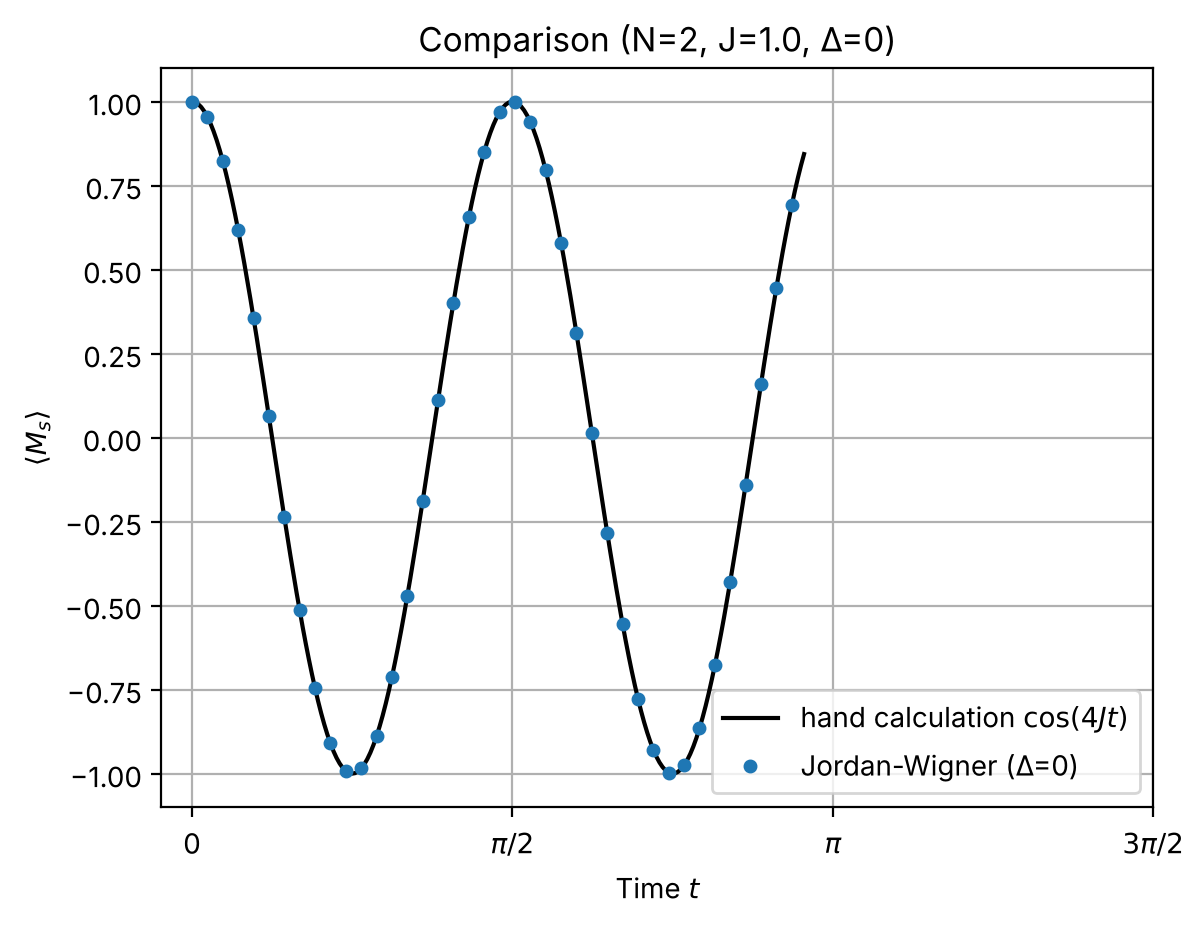

In [2]:
# 例: N=2, J=1, Δ=0
N = 2
J = 1.0
A, B, const = xxz_free_fermion(N, J)
print("A =\n", A)
eps = quasiparticle_energies(bdg_matrix(A, B))
print(f"1粒子エネルギー ε = {eps}  (手計算: |±2J| = 2)")
print(f"基底エネルギー E0 (JW)        = {ground_energy(A, B, const):.6f}  (手計算: -2J = {-2 * J:.6f})")
print(f"基底エネルギー E0 (厳密対角化) = {ground_state(hamiltonian(N, J, 0.0))[0]:.6f}")

ts = np.linspace(0, 3, 200)
ms = ms_jw(N, J, ts)
T = np.pi / 2
plt.plot(ts, np.cos(4 * J * ts), "k-", label=r"hand calculation $\cos(4Jt)$")
plt.plot(ts[::5], ms[::5], "o", ms=4, label="Jordan-Wigner (Δ=0)")
plt.xticks([k * T for k in range(4)], ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$"])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Comparison (N={N}, J={J}, Δ=0)")
plt.legend(loc="lower right")
plt.grid()
plt.show()

$n=2$では手計算と一致した。大きな$n$での厳密対角化との比較や、ベッセル関数$J_0(8Jt)$との比較は[12_staggered_magnetization.ipynb](12_staggered_magnetization.ipynb)で行う。

## 4. $\Delta\neq0$：Jordan-Wigner変換で解けない理由

$\Delta\neq0$では、2節の$4J\Delta\sum_jn_jn_{j+1}$が残る。[methods/02_jordan_wigner.ipynb](../../methods/02_jordan_wigner.ipynb)の5節で述べたように、4次の項が1つでもあると、$[H, c_j]$に$c^\dagger cc$の3次の項が現れ、運動方程式が$2n$個の演算子で閉じない。固有状態も1粒子モードの占有の組み合わせでは書けなくなる。

実際、$n=2$では粒子が1個の部分空間（$\ket{01}, \ket{10}$）に$n_0n_1$は効かないので$\Delta$は定数の差にしか現れなかったが、$n\ge3$で2個の粒子が隣り合える部分空間では、1粒子エネルギーの和では固有値が表せなくなる。

それでもXXZ模型は**可積分**であり、Bethe仮説で厳密に解ける。以下では、[methods/06_bethe_ansatz.ipynb](../../methods/06_bethe_ansatz.ipynb)の手順をXXZ模型に適用する。Bethe仮説では**周期境界条件**を使う。

## 5. Bethe仮説

### 5.1 参照状態と1粒子（マグノン）

- **参照状態**：$\ket{\Omega} = \ket{0\cdots0}$（全スピンが$Z=+1$）。$XY$項は$\ket{\Omega}$に作用すると0で、$ZZ$項はすべてのボンドで$+1$なので
  \begin{equation}
  H\ket{\Omega} = E_\Omega\ket{\Omega},\quad E_\Omega = J\Delta n\qquad(\text{周期境界条件、ボンドは}n\text{本})
  \end{equation}
- **1粒子**：サイト$x$だけ$\ket{1}$にした状態$\ket{x}$を考える。$ZZ$項は$x$の両隣の2本のボンドで$+1\to-1$と変わるので、エネルギーは$E_\Omega - 4J\Delta$になる。$XY$項は$\ket{x}$を$\ket{x\pm1}$に振幅$2J$で移す。したがって平面波$\sum_xe^{ikx}\ket{x}$は固有状態で
  \begin{equation}
  \varepsilon(k) = 4J\left(\cos k - \Delta\right)
  \end{equation}
  が1粒子エネルギー（マグノンの分散）である。$J>0$なので$k = \pi$で最小になる。

### 5.2 2粒子の散乱行列

2節のフェルミオンの形と同じく、マグノンは1つのサイトに1個までしか入れない粒子で、振幅$t = 2J$のホッピングと、隣り合ったときの相互作用$V = 4J\Delta$をもつ（2個が隣り合うと、反転するボンドが4本ではなく2本になるので、独立な2個に比べて$+4J\Delta$）。これは一般論の4節の例1そのもので、$V/t = 2\Delta$を代入すると
\begin{equation}
S(k_1, k_2) = \frac{A_{21}}{A_{12}} = -\frac{1 + e^{i(k_1+k_2)} - 2\Delta e^{ik_2}}{1 + e^{i(k_1+k_2)} - 2\Delta e^{ik_1}}
\end{equation}
を得る。

- $\Delta = 0$では$S = -1$で、自由フェルミオンと同じ（3節）。
- $|S| = 1$、$S(k_1, k_2)S(k_2, k_1) = 1$が確かめられる。

> **導出**（一般論の例1の接触条件）：$x_2 = x_1+1$の配置で、離れた配置の方程式に現れる「存在しない配置」の寄与$t[\psi(x,x) + \psi(x+1,x+1)]$が、相互作用$V\psi(x,x+1)$と等しいという条件に
> $\psi(x_1,x_2) = A_{12}e^{i(k_1x_1+k_2x_2)} + A_{21}e^{i(k_2x_1+k_1x_2)}$を代入すると
> \begin{equation}
> t(A_{12} + A_{21})\left(1 + e^{i(k_1+k_2)}\right) = V\left(A_{12}e^{ik_2} + A_{21}e^{ik_1}\right)
> \end{equation}
> となる。$A_{21}/A_{12}$について解くと上の$S$になる。

### 5.3 Bethe方程式

XXZ模型では3粒子以上の散乱も2粒子の散乱の積に因子化する（可積分性）。一般論の6節より、周期境界条件のBethe方程式は
\begin{equation}
e^{ik_jn} = \prod_{l\neq j}S(k_l, k_j)\qquad(j = 1, \dots, M)
\end{equation}
で、エネルギーは
\begin{equation}
E = J\Delta n + \sum_{j=1}^{M}4J\left(\cos k_j - \Delta\right)
\end{equation}
である。

### 5.4 ラピディティ

$-1<\Delta<1$では$\Delta = \cos\gamma$（$0<\gamma<\pi$）とおき、運動量$k$の代わりにラピディティ$\lambda$を
\begin{equation}
e^{ik} = \frac{\sinh(\lambda + i\gamma/2)}{\sinh(\lambda - i\gamma/2)}
\end{equation}
で導入する。$\lambda = 0$で$k = \pi$、$\lambda\to\pm\infty$で$k\to\pm\gamma$なので、実数の$\lambda$は$\gamma<k<2\pi-\gamma$の運動量（分散の底のまわり）を表す。代入して整理すると、散乱行列が差$\lambda_j - \lambda_l$だけで書ける。
\begin{equation}
S(k_l, k_j) = \frac{\sinh(\lambda_j - \lambda_l + i\gamma)}{\sinh(\lambda_j - \lambda_l - i\gamma)}
\end{equation}
よってBethe方程式は
\begin{equation}
\left[\frac{\sinh(\lambda_j + i\gamma/2)}{\sinh(\lambda_j - i\gamma/2)}\right]^n = \prod_{l\neq j}\frac{\sinh(\lambda_j - \lambda_l + i\gamma)}{\sinh(\lambda_j - \lambda_l - i\gamma)}
\end{equation}
となる。1粒子エネルギーは
\begin{equation}
\varepsilon(\lambda) = 4J(\cos k - \Delta) = -\frac{4J\sin^2\gamma}{\cosh2\lambda - \cos\gamma}
\end{equation}
で、実数の$\lambda$では必ず負になる（$\lambda\to\pm\infty$で0）。

- **対数形**

  $\theta_m(\lambda) = 2\arctan\left[\cot\frac{m\gamma}{2}\tanh\lambda\right]$とおくと
  \begin{equation}
  \frac{\sinh(\lambda + im\gamma/2)}{\sinh(\lambda - im\gamma/2)} = -e^{-i\theta_m(\lambda)},\qquad k = \pi - \theta_1(\lambda)
  \end{equation}
  と書けるので、Bethe方程式の対数をとると
  \begin{equation}
  n\,\theta_1(\lambda_j) = 2\pi I_j + \sum_{l\neq j}\theta_2(\lambda_j - \lambda_l)
  \end{equation}
  となる。両辺の$-1$の個数から、量子数$I_j$は$n - M$が奇数なら整数、偶数なら半整数である。

- **他の$\Delta$**：$\Delta = 1$と$\Delta>1$でも同じ形の方程式になる（$\Delta=1$は$\gamma\to0$の極限で$\lambda$を$\gamma$倍に縮めたもの）。

  | $\Delta$ | 運動量 $e^{ik}$ | $\theta_m(\lambda)$ | $\varepsilon(\lambda)$ |
  |---|---|---|---|
  | $-1<\Delta<1$（$\Delta = \cos\gamma$） | $\dfrac{\sinh(\lambda+i\gamma/2)}{\sinh(\lambda-i\gamma/2)}$ | $2\arctan\left[\cot\frac{m\gamma}{2}\tanh\lambda\right]$ | $-\dfrac{4J\sin^2\gamma}{\cosh2\lambda - \cos\gamma}$ |
  | $\Delta = 1$ | $\dfrac{\lambda + i/2}{\lambda - i/2}$ | $2\arctan\dfrac{2\lambda}{m}$ | $-\dfrac{2J}{\lambda^2 + 1/4}$ |
  | $\Delta>1$（$\Delta = \cosh\eta$） | $\dfrac{\sin(\lambda+i\eta/2)}{\sin(\lambda-i\eta/2)}$ | $2\arctan\left[\coth\frac{m\eta}{2}\tan\lambda\right]$ | $-\dfrac{4J\sinh^2\eta}{\cosh\eta - \cos2\lambda}$ |

  $\Delta>1$では$\lambda$は$-\pi/2<\lambda\le\pi/2$の範囲を動き、$\theta_m$は$\tan\lambda$の不連続をまたいで連続につなぐ。

### 5.5 基底状態

$n$が偶数のとき、基底状態は$M = n/2$（$\sum_jZ_j = 0$）の部分空間にあり（[01_exact_diag.ipynb](01_exact_diag.ipynb)の3節）、量子数を隙間なく並べた
\begin{equation}
I_j = -\frac{M-1}{2}, -\frac{M-3}{2}, \dots, \frac{M-1}{2}
\end{equation}
の実数解で表される。$\varepsilon(\lambda)<0$なので、マグノンを入れるほどエネルギーは下がるが、マグノンどうしの散乱（排他）のために$n/2$個で止まる。基底エネルギーは
\begin{equation}
E_0 = J\Delta n + \sum_{j=1}^{n/2}\varepsilon(\lambda_j)
\end{equation}
である。$n\to\infty$の値（Hulthén, Yang-Yangの結果）と有限サイズ補正は[11_ground_state.ipynb](11_ground_state.ipynb)で調べる。

## 6. $n=2$の手計算（Bethe仮説）

$n=2$、周期境界条件の場合を手で計算する。周期境界条件の$n=2$ではボンド$(0,1)$と$(1,0)$が同じボンドを2回数えるので、ハミルトニアンは開放境界の2倍$H_{\mathrm{PBC}} = 2J(X_0X_1 + Y_0Y_1 + \Delta Z_0Z_1)$になり、基底エネルギーは$2\times(-J(2+\Delta)) = -4J - 2J\Delta$である。

- **運動量で解く**：$M = 1$なので散乱はなく、Bethe方程式は$e^{2ik} = 1$、つまり$k = 0, \pi$。
  $$
  E = E_\Omega + \varepsilon(k) = 2J\Delta + 4J(\cos k - \Delta)
  $$
  より$k = \pi$で$E = -4J - 2J\Delta$、$k=0$で$E = 4J - 2J\Delta$となり、それぞれ一重項と三重項$\ket{\psi_+}$の（2倍の）エネルギーと一致する。

- **ラピディティで解く**：$M = 1$、$n - M = 1$は奇数なので$I_1 = 0$。対数形の方程式は$2\theta_1(\lambda_1) = 0$なので$\lambda_1 = 0$（$k = \pi$）で、
  $$
  E_0 = 2J\Delta + \varepsilon(0) = 2J\Delta - \frac{4J\sin^2\gamma}{1 - \cos\gamma} = 2J\Delta - 4J(1 + \cos\gamma) = -4J - 2J\Delta
  $$
  となり一致する。

散乱の効果が現れるのは$M\ge2$からである。次のコードで、$n=4$〜$12$（$M = 2$〜$6$）のBethe方程式を数値的に解き、厳密対角化と比べる。

## 7. コードで確かめる（Bethe仮説）

In [3]:
from math import comb
from scipy.sparse.linalg import eigsh

J = 1.0
Delta = 0.5

# n=2: 手計算 E0 = -4J - 2JΔ（周期境界、ボンドを2回数える）
E_b, lam, res = xxz_bethe_ground_state(2, J, Delta)
print(f"n=2: λ = {lam},  E0 (Bethe) = {E_b:.6f},  E0 (厳密対角化) = {ground_state(hamiltonian(2, J, Delta, pbc=True))[0]:.6f},"
      f"  手計算 = {-4 * J - 2 * J * Delta:.6f}")

# n=4〜12: Bethe 方程式の数値解と厳密対角化（m = n/2 のブロック）
print("\n n   M   E0 (Bethe)          E0 (厳密対角化)      差        残差")
for n in [4, 6, 8, 10, 12]:
    E_b, lam, res = xxz_bethe_ground_state(n, J, Delta)
    E_ed = eigsh(xxz_hamiltonian_sector(n, J, Delta, n // 2, pbc=True), k=1, which="SA")[0][0]
    print(f"{n:2d}  {n // 2:2d}  {E_b:.12f}  {E_ed:.12f}  {abs(E_b - E_ed):.1e}  {res:.1e}")

n=2: λ = [0.],  E0 (Bethe) = -5.000000,  E0 (厳密対角化) = -5.000000,  手計算 = -5.000000

 n   M   E0 (Bethe)          E0 (厳密対角化)      差        残差
 4   2  -6.744562646538  -6.744562646538  0.0e+00  1.1e-16
 6   3  -9.472135955000  -9.472135955000  1.8e-15  2.2e-16
 8   4  -12.347977420550  -12.347977420549  1.8e-14  6.7e-16
10   5  -15.276131122066  -15.276131122066  7.1e-15  4.4e-16
12   6  -18.229089763322  -18.229089763322  7.1e-15  1.3e-15


Bethe方程式の解は厳密対角化と数値誤差の範囲で一致した。$n=8$の解（ラピディティ$\lambda_j$と運動量$k_j$）を見てみる。

量子数 I_j : [-1.5 -0.5  0.5  1.5]
λ_j        : [-0.5469   -0.135285  0.135285  0.5469  ]
k_j / π    : [1.453231 1.145673 0.854327 0.546769]   (γ/π = 0.3333, 自由フェルミオンなら 2πJ_j/n)
ε(λ_j)     : [-2.585608 -5.588381 -5.588381 -2.585608]
j=0: |e^(ik_j n) - Π S(k_l, k_j)| = 2.5e-15
j=1: |e^(ik_j n) - Π S(k_l, k_j)| = 1.8e-15
j=2: |e^(ik_j n) - Π S(k_l, k_j)| = 8.7e-16
j=3: |e^(ik_j n) - Π S(k_l, k_j)| = 7.9e-16


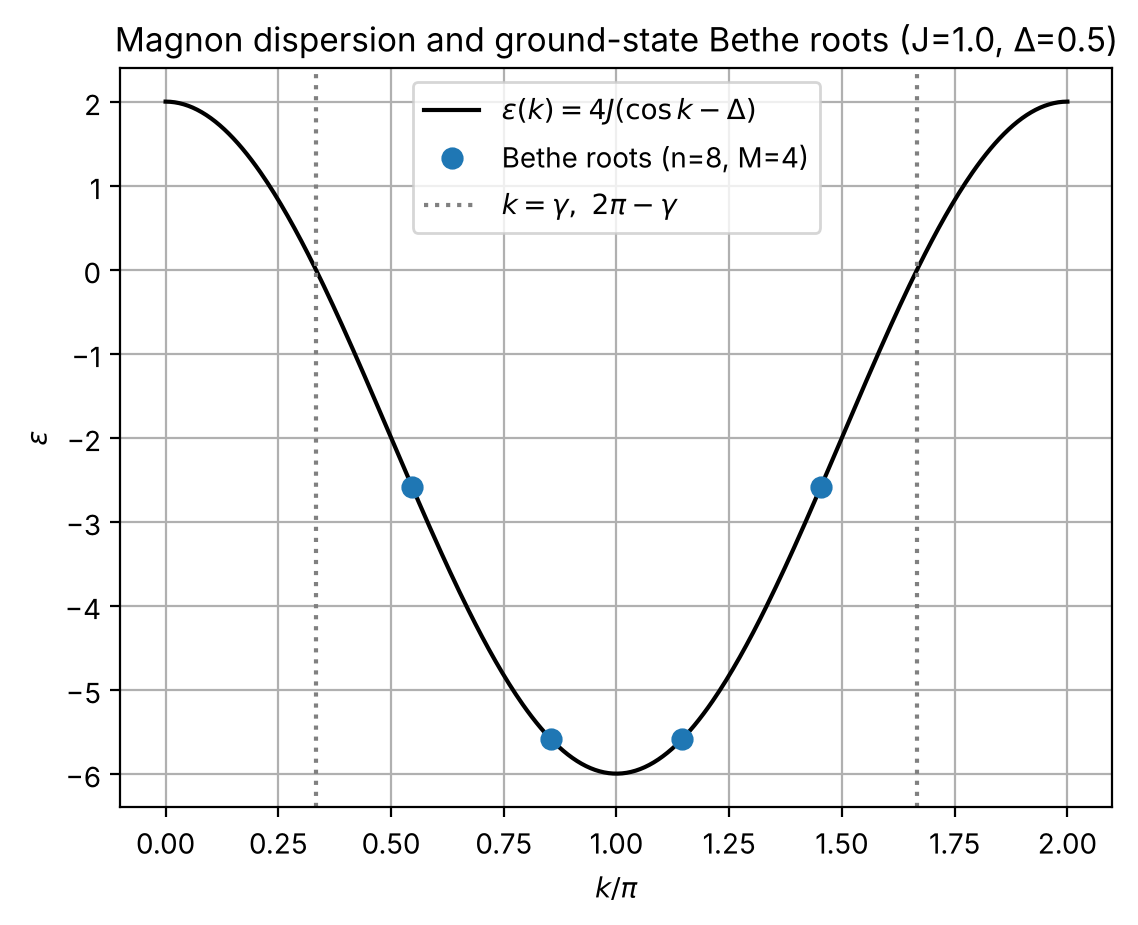

In [4]:
n = 8
theta1, theta2, theta1_inv, eps = xxz_bethe_functions(J, Delta)
E_b, lam, res = xxz_bethe_ground_state(n, J, Delta)
k = np.pi - theta1(lam)
gamma = np.arccos(Delta)
print("量子数 I_j :", np.arange(n // 2) - (n // 2 - 1) / 2)
print("λ_j        :", np.round(lam, 6))
print("k_j / π    :", np.round(k / np.pi, 6), f"  (γ/π = {gamma / np.pi:.4f}, 自由フェルミオンなら 2πJ_j/n)")
print("ε(λ_j)     :", np.round(eps(lam), 6))

# 運動量の形の Bethe 方程式 e^{ik_j n} = Π_{l≠j} S(k_l, k_j) も満たしていることを確認
def S(k1, k2):
    return -(1 + np.exp(1j * (k1 + k2)) - 2 * Delta * np.exp(1j * k2)) / (1 + np.exp(1j * (k1 + k2)) - 2 * Delta * np.exp(1j * k1))

for j in range(n // 2):
    rhs = np.prod([S(k[l], k[j]) for l in range(n // 2) if l != j])
    print(f"j={j}: |e^(ik_j n) - Π S(k_l, k_j)| = {abs(np.exp(1j * k[j] * n) - rhs):.1e}")

# ε(k) = 4J(cos k - Δ) で描いた分散と、基底状態のマグノンの位置
kk = np.linspace(0, 2 * np.pi, 400)
plt.plot(kk / np.pi, 4 * J * (np.cos(kk) - Delta), "k-", label=r"$\varepsilon(k) = 4J(\cos k - \Delta)$")
plt.plot(k / np.pi, eps(lam), "o", ms=7, label=f"Bethe roots (n={n}, M={n // 2})")
plt.axvline(gamma / np.pi, color="gray", ls=":")
plt.axvline(2 - gamma / np.pi, color="gray", ls=":", label=r"$k = \gamma,\ 2\pi - \gamma$")
plt.xlabel(r"$k/\pi$")
plt.ylabel(r"$\varepsilon$")
plt.title(f"Magnon dispersion and ground-state Bethe roots (J={J}, Δ={Delta})")
plt.legend()
plt.grid()
plt.show()

基底状態のマグノンは、分散の底$k=\pi$のまわりに詰まっている（フェルミの海に相当）。ただし、自由フェルミオンのように$2\pi/n$間隔には並ばず、散乱の位相のぶんだけずれている。

$n$を大きくしたときの比較（$n = 1000$程度までのBethe仮説の計算、熱力学極限、VQE）は[11_ground_state.ipynb](11_ground_state.ipynb)で行う。

なお、Bethe仮説で簡単に求まるのは固有エネルギーであり、Néel状態からの時間発展のような量は、固有状態の波動関数（$M!$項の和）を使う必要があるので簡単には求まらない。$\Delta\neq0$の$m_s(t)$は、厳密対角化とTrotter分解で計算する（[12_staggered_magnetization.ipynb](12_staggered_magnetization.ipynb)）。

---
**前へ**: [01 厳密対角化](01_exact_diag.ipynb)　｜　**次へ**: [03 Trotter分解](03_trotter.ipynb)